# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [46]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [47]:
df = pd.read_csv('data/AviationData_Cleaned.csv')
df.head(5)

C:\Users\amira\AppData\Local\Temp\ipykernel_32980\460068345.py:1: DtypeWarning: Columns (0: Latitude, 1: Longitude, 2: Broad.phase.of.flight) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/AviationData_Cleaned.csv')


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.People,Fatal.Serious.Injuries,Fatal_Severe_Injury_Rate,Destroyed,Make.Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0.0,0.0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,0.0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0.0,0.0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0.0,0.0,PIPER PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,0.0,CESSNA 140


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [48]:
small_plane = df[df['Total.People'] < 20]
large_plane = df[df['Total.People'] >= 20]

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

<Axes: xlabel='Make'>

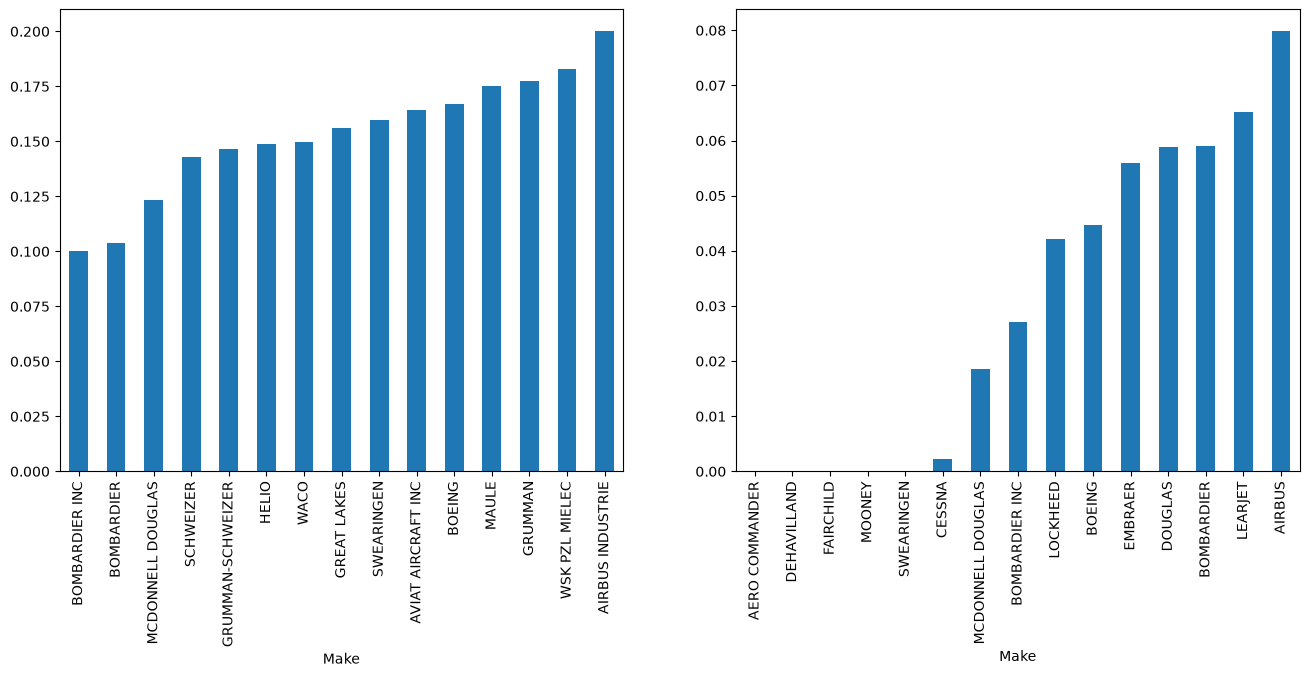

In [49]:
small_plane_mean = small_plane.groupby('Make')['Fatal_Severe_Injury_Rate'].mean().sort_values().head(15)
large_plane_mean = large_plane.groupby('Make')['Fatal_Severe_Injury_Rate'].mean().sort_values().head(15)

fig, axes = plt.subplots(1, 2, figsize=(16,6))
small_plane_mean.plot(kind='bar', ax=axes[0])
large_plane_mean.plot(kind='bar', ax=axes[1])


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'HELIO'),
  Text(1, 0, 'SWEARINGEN'),
  Text(2, 0, 'GREAT LAKES'),
  Text(3, 0, 'GRUMMAN-SCHWEIZER'),
  Text(4, 0, 'WACO'),
  Text(5, 0, 'SCHWEIZER'),
  Text(6, 0, 'MCDONNELL DOUGLAS'),
  Text(7, 0, 'BOMBARDIER'),
  Text(8, 0, 'AVIAT AIRCRAFT INC'),
  Text(9, 0, 'BOMBARDIER INC')])

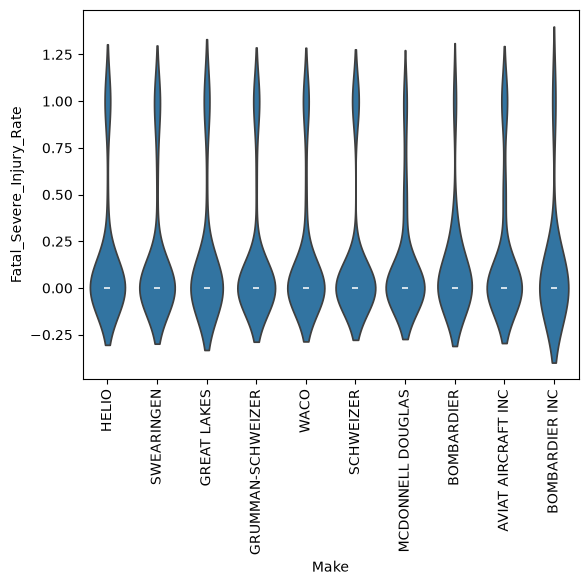

In [50]:
small_plane_mean = small_plane.groupby('Make')['Fatal_Severe_Injury_Rate'].mean().sort_values().head(10)
chosen_makes = small_plane_mean.index
small_plane_10 = small_plane.query('Make in @chosen_makes')
sns.violinplot(data=small_plane_10, x='Make', y='Fatal_Severe_Injury_Rate')
plt.xticks(rotation=90)



**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'SWEARINGEN'),
  Text(1, 0, 'BOEING'),
  Text(2, 0, 'MCDONNELL DOUGLAS'),
  Text(3, 0, 'LOCKHEED'),
  Text(4, 0, 'FAIRCHILD'),
  Text(5, 0, 'CESSNA'),
  Text(6, 0, 'MOONEY'),
  Text(7, 0, 'AERO COMMANDER'),
  Text(8, 0, 'BOMBARDIER INC'),
  Text(9, 0, 'DEHAVILLAND')])

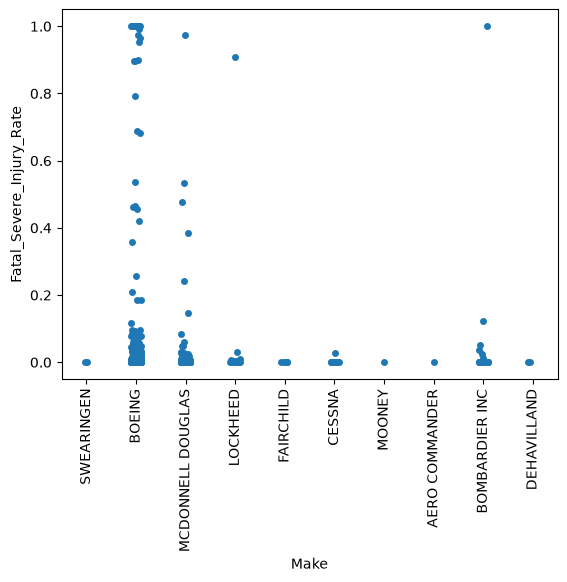

In [51]:
large_plane_mean = large_plane.groupby('Make')['Fatal_Severe_Injury_Rate'].mean().sort_values().head(10)
chosen_makes_large = large_plane_mean.index
large_plane_10 = large_plane.query('Make in @chosen_makes_large')
sns.stripplot(data=large_plane_10, x='Make', y='Fatal_Severe_Injury_Rate')
plt.xticks(rotation=90)

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [ ]:
small_plane_destruction = small_plane.groupby('Make')['Destroyed'].mean().sort_values().head(15)
large_plane_destruction = large_plane.groupby('Make')['Destroyed'].mean().sort_values().head(15)
small_plane_destruction
large_plane_destruction



Make
AERO COMMANDER               0.000000
CESSNA                       0.000000
DEHAVILLAND                  0.000000
RAYTHEON AIRCRAFT COMPANY    0.000000
SWEARINGEN                   0.000000
BOMBARDIER INC               0.037037
BOMBARDIER                   0.055556
LOCKHEED                     0.071429
MCDONNELL DOUGLAS            0.072072
BOEING                       0.084541
EMBRAER                      0.100000
DOUGLAS                      0.160000
AIRBUS                       0.160000
AIRBUS INDUSTRIE             0.210526
FAIRCHILD                    0.250000
Name: Destroyed, dtype: float64

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [53]:
## For small airplanes, I recommend considering BOMBARDIER and AVIAT AIRCRAFT INC. BOMBARDIER had a lower average fatal/serious injury fraction of 10.4% with a destruction rate of 5%.AVIAT AIRCRAFT INC had a higher injury fraction of 16.4%,but a lower destruction rate of 4%
## These results are based on 33 and 76 accident records respectively, so the recommendations should be considered carefully. 

## For large airplanes, I recommend considering MCDONNEL DOUGLAS and BOMBARDIER INC. MCDONNELL DOUGLAS had a lower average fatal/serious injury fraction of 1.85% with a destruction rate of 7.21% based on 187 accident records. BOMBARDIER INC had an injury fraction of 2.71% and a lower destruction rate of 3.70%, based on 46 records.

# As for the stripplot large airplane - most large airplane accident records had fatal/serious injury fractions near zero. BOEING and MCDONNEL DOUGLAS had several accidents with much higher fractions. This could mean that low averages can still include severe individual accidents

# As for the small airplane violin plots, htey are widest near zero which shows that the most recorded accidents had low fatal/serious injury fractions. 

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36],
 [Text(0, 0, 'BOEING 737-200'),
  Text(1, 0, 'LOCKHEED L-1011-385-1'),
  Text(2, 0, 'BOEING 727-200'),
  Text(3, 0, 'DOUGLAS DC-9-31'),
  Text(4, 0, 'MCDONNELL DOUGLAS DC-10-10'),
  Text(5, 0, 'MCDONNELL DOUGLAS DC-9-51'),
  Text(6, 0, 'BOEING 767'),
  Text(7, 0, 'MCDONNELL DOUGLAS DC-10-30'),
  Text(8, 0, 'MCDONNELL DOUGLAS DC-9-82'),
  Text(9, 0, 'BOEING 727-223'),
  Text(10, 0, 'BOEING 727'),
  Text(11, 0, 'BOEING 727-225'),
  Text(12, 0, 'MCDONNELL DOUGLAS MD-80'),
  Text(13, 0, 'BOEING 737-300'),
  Text(14, 0, 'BOEING 737'),
  Text(15, 0, 'BOEING 737-222'),
  Text(16, 0, 'BOEING 747'),
  Text(17, 0, 'BOEING 767-332'),
  Text(18, 0, 'BOEING 757'),
  Text(19, 0, 'MCDONNELL DOUGLAS MD-88'),
  Text(20, 0, 'BOEING 737-400'),
  Text(21, 0, 'BOEING 757-232'),
  Text(22, 0, 'BOEI

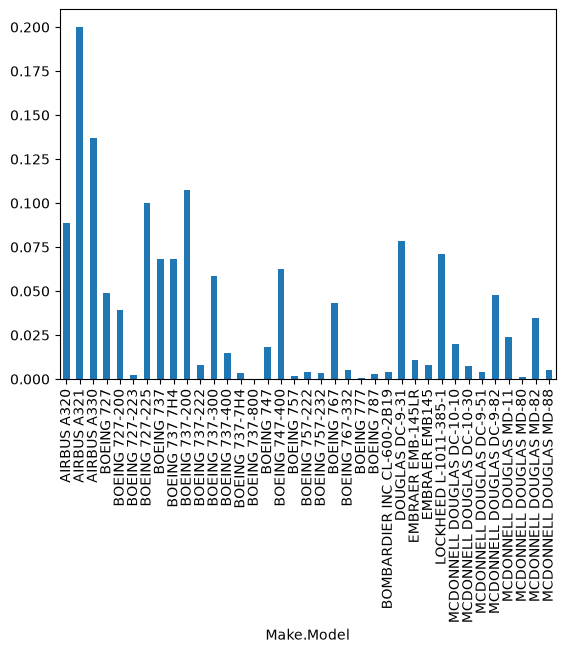

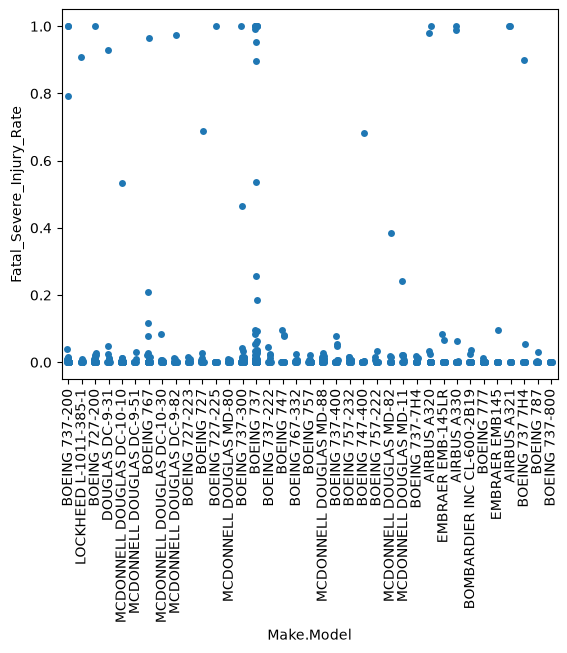

In [59]:
large_model_count = large_plane.groupby('Make.Model')['Fatal_Severe_Injury_Rate'].count()
individual_examples = large_model_count[large_model_count >= 10]
chosen_models_large = individual_examples.index
large_plane_filtered = large_plane.query('`Make.Model` in @chosen_models_large')
large_plane_filtered_mean = large_plane_filtered.groupby('Make.Model')['Fatal_Severe_Injury_Rate'].mean()

large_plane_filtered_mean.plot(kind='bar')
plt.figure()
sns.stripplot(data=large_plane_filtered, x='Make.Model', y='Fatal_Severe_Injury_Rate')
plt.xticks(rotation=90)


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'WEATHERLY 201B'),
  Text(1, 0, 'PIPER PA-18-180'),
  Text(2, 0, 'PIPER PA-18A 150'),
  Text(3, 0, 'CESSNA C172'),
  Text(4, 0, 'CESSNA 180C'),
  Text(5, 0, 'GRUMMAN G164B'),
  Text(6, 0, 'MAULE MX-7-235'),
  Text(7, 0, 'BEECH 1900D'),
  Text(8, 0, 'DIAMOND AIRCRAFT IND INC DA 20 C1'),
  Text(9, 0, 'AIR TRACTOR AT 602')])

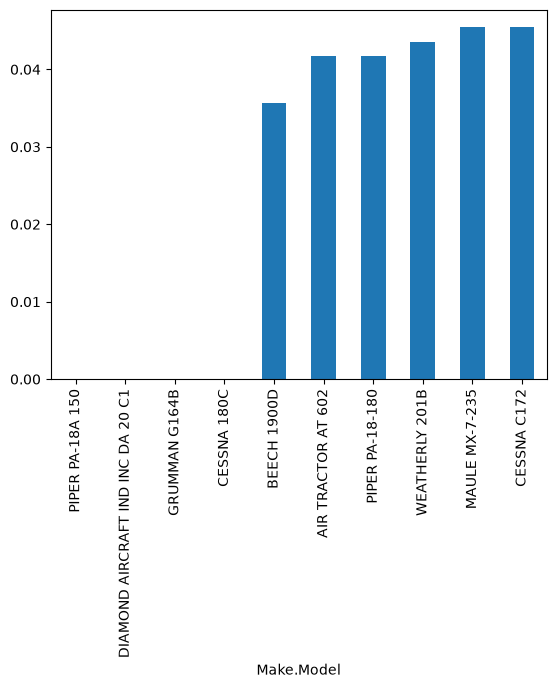

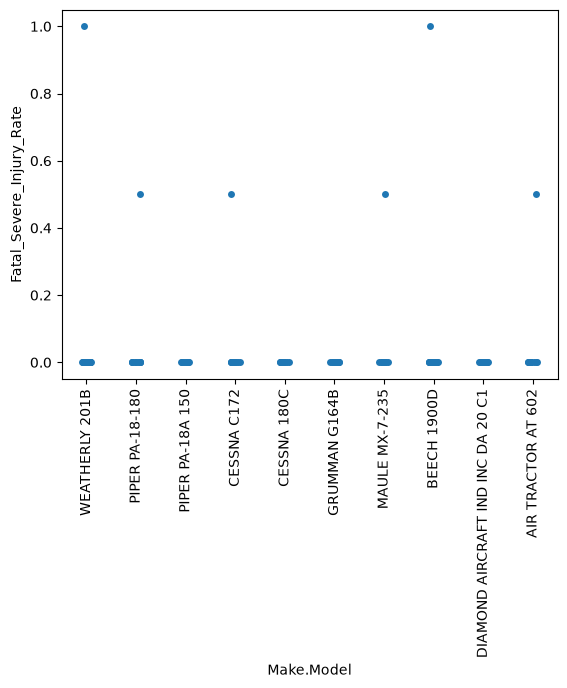

In [58]:
small_model_count = small_plane.groupby('Make.Model')['Fatal_Severe_Injury_Rate'].count()
small_individual_examples = small_model_count[small_model_count >= 10]
chosen_models_small = small_individual_examples.index
small_plane_filtered = small_plane.query('`Make.Model` in @chosen_models_small')
small_plane_filtered_mean = small_plane_filtered.groupby('Make.Model')['Fatal_Severe_Injury_Rate'].mean().sort_values().head(10)
small_plane_filtered_mean.plot(kind='bar')


chosen_small_top10 = small_plane_filtered_mean.index
small_plane_top10 = small_plane_filtered.query('`Make.Model` in @chosen_small_top10')

plt.figure()
sns.stripplot(data=small_plane_top10, x='Make.Model', y='Fatal_Severe_Injury_Rate')
plt.xticks(rotation=90)

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [ ]:
# For the selected small-airplane models, four had no recorded fatal or serious injuries in the valid records. 
# The other six had average injury fractions of approximately 3.6%–4.5%.
# Each model’s average was based on at least 10 valid injury fractions.

# For the selected larger airplane models, BOEING 737-800 had a mean fatal/serious injury fraction of 0%, 
# while AIRBUS A321 had the highest average 20%. 
# Most accident values were near zero, but some reached 100%.


## Recommendation 
# For larger airplanes, I recommend considering BOEING 737-800 and BOEING 777 because they had very low average fatal/serious injury fractions. 
# For smaller airplanes, CESSNA 180C and PIPER PA-18A 150 had no recorded fatal or serious injuries.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [57]:
# Weather Condition

df['Weather.Condition'].value_counts()
df.groupby('Weather.Condition')['Fatal_Severe_Injury_Rate'].mean()
df.groupby('Weather.Condition')['Destroyed'].mean()

# Accidents udner IMC were more severe. The avg fatal/serious injury fraction was 65.9% compared to 22.0% under VMC.
# Aircraft destruction occured in 58.7% of IMC accident records compared to 16.3% under VMC. Again shows association between
# IMC and more severe accident outcomes. 


# Purpose of Flight
df['Purpose.of.flight'].value_counts()
df.groupby('Purpose.of.flight')['Fatal_Severe_Injury_Rate'].mean()
df.groupby('Purpose.of.flight')['Destroyed'].mean()

# Instructional flights had lower average fatal/serious injury fractions (15.3%) and destruction rates (11.0%) 
# than Personal flights (28.5% and 20.5%) and Business flights (34.7% and 30.8%). 
# The results are based on recorded accidents alone.

Purpose.of.flight
ASHO                         1.000000
Aerial Application           0.222258
Aerial Observation           0.284153
Air Drop                     0.200000
Air Race/show                0.391304
Banner Tow                   0.084211
Business                     0.307634
Executive/corporate          0.315985
Ferry                        0.283613
Firefighting                 0.411765
Flight Test                  0.138889
Glider Tow                   0.060606
Instructional                0.110026
Other Work Use               0.227926
PUBS                         0.000000
Personal                     0.205460
Positioning                  0.250562
Public Aircraft              0.256000
Public Aircraft - Federal    0.071429
Public Aircraft - Local      0.166667
Public Aircraft - State      0.038462
Skydiving                    0.208333
Name: Destroyed, dtype: float64